# Music Review Insight Finder: AI-audited labels, GPU smoke test, and LoRA

 **music_insight_AI_AUDITED_training_bundle.zip** is required for Section 2 of this notebook.

All training, validation, and test labels were passed through ChatGPT for an initial audit and then human-reviewed. Original release-group splits are fixed: **140 train / 33 validation / 35 test**, with **21 explicit skips** in the full audit.

**Instructions (Google Colab):** choose a free **T4 GPU** under Runtime → Change runtime type. Use Python 3.10–3.12; if needed, the documented **2026.07** runtime uses Python 3.12. Run section 1, restart the session after installation, then resume at section 2. Upload only the matching bundle when you choose to transfer it to Google's runtime. Run through **GPU smoke test** before continuing. Do not use Run all.

The smoke test runs three small training steps, makes a prediction, and checks that the adapter can be saved and loaded in order to ensure the code is functional. It then removes the temporary adapter. In the original workflow, a successful test was followed by training, evaluation, charts and a results ZIP.


## 1. Runtime and dependencies

In [1]:
import sys, os
assert (3, 10) <= sys.version_info[:2] <= (3, 12), "Use a Python 3.10–3.12 Colab runtime for these pinned dependencies."
import torch
from packaging.version import Version
assert Version(torch.__version__.split("+")[0]) >= Version("2.3"), "This loop needs PyTorch 2.3+; use a fresh compatible Colab runtime."
assert torch.cuda.is_available(), "No CUDA GPU. In Colab choose Runtime > Change runtime type > T4 GPU, if available free."
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory GB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))
assert torch.cuda.get_device_properties(0).total_memory >= 7 * 1024**3, "Use a GPU with at least 7 GiB memory for this configuration."

Python: 3.12.13 PyTorch: 2.11.0+cu128
GPU: Tesla T4
GPU memory GB: 14.6


Install in the fresh Colab runtime only. This preserves Colab's CUDA PyTorch build. **After installation, choose Runtime → Restart session and resume at section 2; do not rerun section 1.** The next section blocks execution in the old process to avoid mixing already-imported packages with replaced binaries. 

In [2]:
import subprocess
packages = ["transformers==4.57.1", "peft==0.17.1", "accelerate==1.10.1", "safetensors==0.6.2",
            "numpy==1.26.4", "pandas==2.2.3", "matplotlib==3.9.4", "scikit-learn==1.6.1"]
subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet"] + packages)
SETUP_NEEDS_RESTART = True
print("Installation finished. NOW choose Runtime > Restart session; then resume at section 2. Do not Run all.")


Installation finished. NOW choose Runtime > Restart session; then resume at section 2. Do not Run all.


## 2. Load the frozen dataset

In [1]:
# This is the user's explicit upload step, not an automatic transfer.
assert not globals().get("SETUP_NEEDS_RESTART", False), "Restart the session after installation, then resume at section 2."
import sys, importlib.metadata
assert (3, 10) <= sys.version_info[:2] <= (3, 12), "Choose a Python 3.10–3.12 runtime, e.g. 2026.07."
expected_versions = {"transformers":"4.57.1", "peft":"0.17.1", "accelerate":"1.10.1", "safetensors":"0.6.2",
                     "numpy":"1.26.4", "pandas":"2.2.3", "matplotlib":"3.9.4", "scikit-learn":"1.6.1"}
for package, expected in expected_versions.items():
    assert importlib.metadata.version(package) == expected, f"Install the notebook's pinned {package} version first."
from google.colab import files
uploaded = files.upload()  # Select music_insight_AI_AUDITED_training_bundle.zip only.
assert len(uploaded) == 1, "Select exactly one matching AI-audited bundle."
archive_name = next(iter(uploaded))
print("Selected:", archive_name)


Saving music_insight_AI_AUDITED_training_bundle.zip to music_insight_AI_AUDITED_training_bundle.zip
Selected: music_insight_AI_AUDITED_training_bundle.zip


In [2]:
from pathlib import Path
import hashlib, json, zipfile, io, tempfile, sys
EXPECTED_CODE_HASHES = {'music_review_pipeline.py': 'fa96fea62b6a8109f07d1785061853dd1c2385e9f239526d3dfd0b28f5cfb94d', 'music_review_training.py': '840f89155cb0527bd9a54824556a208d04670b4b81de07ec5bfcf693053589ce', 'music_review_audit.py': '47cb3594917fd29ca343166bdd49fe7ad9293ad8a9cc50f61eb44d2d4bfbbb39', 'music_review_smoke.py': '570ad8c72a6ff8e6a310a67e743a32e9aee7cb1f7f68d58ea9b64d5ca71dda0c'}
expected_names = {'music_review_pipeline.py', 'requirements_colab_AI_AUDITED.txt', 'provenance/selected_rows_original.json', 'splits/manifest.json', 'splits/validation.csv', 'music_review_audit.py', 'splits/test.csv', 'audited_annotations.csv', 'LABELING_GUIDE.md', 'music_review_smoke.py', 'audit_manifest.json', 'music_review_training.py', 'provenance/frozen_session_manifest.json', 'splits/train.csv', 'bundle_sha256.json'}
EXPECTED_BUNDLE_SHA256 = 'e036da628085c1bd1f262b06776f4e2f3f0666fa04cc3755e63799e11bf634c6'
assert hashlib.sha256(uploaded[archive_name]).hexdigest() == EXPECTED_BUNDLE_SHA256, "Wrong or changed bundle; use the ZIP delivered with notebook 06."
WORK_DIR = Path(tempfile.mkdtemp(prefix="music_insight_", dir="/content"))
with zipfile.ZipFile(io.BytesIO(uploaded[archive_name])) as archive:
    assert len(archive.namelist()) == len(expected_names) and set(archive.namelist()) == expected_names, "Unexpected archive members."
    assert sum(info.file_size for info in archive.infolist()) < 30_000_000, "Unexpectedly large bundle."
    blobs = {name: archive.read(name) for name in expected_names}
hashes = json.loads(blobs["bundle_sha256.json"])
assert set(hashes) == expected_names - {"bundle_sha256.json"}
for name, content in blobs.items():
    if name != "bundle_sha256.json":
        assert hashlib.sha256(content).hexdigest() == hashes[name], "Changed archive content: " + name
for name, expected in EXPECTED_CODE_HASHES.items():
    assert hashlib.sha256(blobs[name]).hexdigest() == expected, "Helper differs from this notebook. Rebuild the bundle with its matching files."
for name, content in blobs.items():
    path = WORK_DIR / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
sys.path.insert(0, str(WORK_DIR))
import music_review_pipeline as pipeline
import music_review_training as training
import music_review_audit as audit_validation
import music_review_smoke as smoke
splits = {name: pipeline.load_csv(WORK_DIR / "splits" / (name + ".csv")) for name in ("train", "validation", "test")}
manifest = json.loads((WORK_DIR / "splits" / "manifest.json").read_text())
for name, rows in splits.items():
    assert pipeline.digest(rows) == manifest["split_sha256"][name], "Split data was edited."
    assert all(row["label"] in pipeline.LABELS for row in rows)
pipeline.check_splits(splits)
print("Integrity checked:", {name: len(rows) for name, rows in splits.items()})
print("Work folder:", WORK_DIR)


Integrity checked: {'train': 140, 'validation': 33, 'test': 35}
Work folder: /content/music_insight_j_elzfsr


In [3]:
manifest = audit_validation.validate_audited_splits(WORK_DIR, splits)
print("PASS: source fields, frozen group membership, row counts, hashes, and explicit AI-assisted provenance.")
print("All evaluation labels are AI-audited; NOT independent human gold.")
print("Labeling methods:", manifest["labeling_method"])
GPU_SMOKE_PASSED = False


PASS: source fields, frozen group membership, row counts, hashes, and explicit AI-assisted provenance.
All evaluation labels are AI-audited; NOT independent human gold.
Labeling methods: {'train': 'AI-assisted: passage-by-passage audit by Codex after original human review; NOT independent human labels', 'validation': 'AI-assisted: passage-by-passage audit by Codex after original human review; NOT independent human labels', 'test': 'AI-assisted: passage-by-passage audit by Codex after original human review; NOT independent human labels'}


## 3. Model and experiment settings

In [4]:
import os, random, math, gc, platform, importlib.metadata
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["WANDB_DISABLED"] = "true"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed, get_linear_schedule_with_warmup
from huggingface_hub import model_info
from peft import LoraConfig, TaskType, get_peft_model, PeftModel
from torch.utils.data import DataLoader
from functools import partial

assert torch.cuda.is_available(), "Select a free CUDA GPU runtime first."
SEED = manifest["seed"]
set_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = torch.device("cuda")
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
# Resolve once and save the exact commit. For a reproduction, replace None with the recorded SHA.
MODEL_REVISION = None
RESOLVED_REVISION = MODEL_REVISION or model_info(MODEL_ID).sha
OUTPUT = WORK_DIR / "results"
OUTPUT.mkdir(exist_ok=False)
VERSIONS = {name: importlib.metadata.version(name) for name in
            ("torch", "transformers", "peft", "accelerate", "safetensors", "numpy", "pandas", "scikit-learn")}
settings = {"model": MODEL_ID, "revision": RESOLVED_REVISION, "model_license": "Apache-2.0",
            "seed": SEED, "epochs": 3, "batch_size": 2, "gradient_accumulation": 4,
            "learning_rate": 2e-4, "max_sequence_length": 512, "max_passage_tokens": 256,
            "lora_r": 8, "lora_alpha": 16, "lora_dropout": .05,
            "lora_targets": ["q_proj", "v_proj"], "versions": VERSIONS,
            "gpu": torch.cuda.get_device_name(0), "mixed_precision": str(AMP_DTYPE),
            "split_manifest": manifest, "status": "configured_not_trained"}
settings["labeling_method"] = manifest["labeling_method"]
settings["frozen_session_manifest_sha256"] = manifest["frozen_session_manifest_sha256"]
settings["audit_manifest_sha256"] = manifest["audit_manifest_sha256"]
settings["training_bundle_sha256"] = EXPECTED_BUNDLE_SHA256
settings["independent_human_evaluation"] = False
settings["evaluation_interpretation"] = manifest["interpretation"]
pipeline.save_json(OUTPUT / "settings.json", settings)
print(VERSIONS)
print("Exact model revision:", RESOLVED_REVISION)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=RESOLVED_REVISION, trust_remote_code=False)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
training.label_token_ids(tokenizer)

def load_base_model():
    # Frozen base weights in FP32; autocast handles operations, avoiding FP16 optimizer pitfalls.
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=RESOLVED_REVISION,
        torch_dtype=torch.float32, trust_remote_code=False, use_safetensors=True,
        attn_implementation="eager").to(DEVICE)

model = load_base_model()
model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False
print("Downloaded base model; not adapted yet.")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


{'torch': '2.11.0+cu128', 'transformers': '4.57.1', 'peft': '0.17.1', 'accelerate': '1.10.1', 'safetensors': '0.6.2', 'numpy': '1.26.4', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'}
Exact model revision: 7ae557604adf67be50417f59c2c2f167def9a775


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Downloaded base model; not adapted yet.


[Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct) is an Apache-2.0 causal language model. Both versions receive the same chat prompt and are classified by ranking the next-token scores for A, B, and C. This constrains predictions to the three categories; scores normalized over those codes are not calibrated confidence estimates.

The code records the model's exact revision, dataset hashes, random seed, package versions, GPU, and training settings. Model weights are loaded as safe tensors with remote custom code disabled. Review text is processed inside the selected runtime rather than sent to a hosted inference endpoint.

## GPU smoke test — run this before the full experiment

Six training passages and three validation probes only; no test examples. Checks finite loss/gradients, an actual adapter update, safe checkpoint saving, matching predictions after reload, and removal of the smoke adapter without merging. A PASS is execution evidence, not a performance result. If this fails, stop and share the full error. The original model weights and full frozen splits are reused for the main experiment.


In [5]:
# This cell starts only a tiny smoke experiment when Aaron runs it.
model, smoke_record = smoke.run_smoke_test(model, tokenizer, splits["train"], splits["validation"],
    DEVICE, AMP_DTYPE, OUTPUT / "smoke_test")
GPU_SMOKE_PASSED = smoke_record["status"] == "PASS"
set_seed(SEED)  # Fresh deterministic adapter initialization for the main experiment.
print("GPU SMOKE TEST PASS — update, prediction, save/reload, cleanup verified; test rows used: 0.")
print("Continue at section 4 to run the main validation and three-epoch experiment.")


/usr/local/lib/python3.12/dist-packages/peft/tuners/tuners_utils.py:196: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


GPU SMOKE TEST PASS — update, prediction, save/reload, cleanup verified; test rows used: 0.
Continue at section 4 to run the main validation and three-epoch experiment.


## 4. Unadapted model on validation data

In [6]:
base_validation_predictions, _ = training.predict_closed_set(
    model, tokenizer, splits["validation"], DEVICE, AMP_DTYPE)
base_validation_metrics = pipeline.evaluate_predictions(splits["validation"], base_validation_predictions)
pipeline.save_json(OUTPUT / "unadapted_validation.json", base_validation_metrics)
print({k: base_validation_metrics[k] for k in ("n", "accuracy", "macro_f1")})
print("The test set remains unused until the final comparison.")

{'n': 33, 'accuracy': 0.30303030303030304, 'macro_f1': 0.23015873015873015}
The test set remains unused until the final comparison.


## 5. LoRA fine-tuning

In [7]:
assert GPU_SMOKE_PASSED, "Run the GPU smoke test successfully first."
# Prompt tokens and padding are masked out of the training loss.
train_examples = [training.supervised_example(tokenizer, r["text"], r["label"]) for r in splits["train"]]
validation_examples = [training.supervised_example(tokenizer, r["text"], r["label"]) for r in splits["validation"]]
collator = partial(training.collate_examples, pad_token_id=tokenizer.pad_token_id)
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_examples, batch_size=settings["batch_size"], shuffle=True,
                          generator=generator, collate_fn=collator, num_workers=0)
validation_loader = DataLoader(validation_examples, batch_size=2, shuffle=False, collate_fn=collator, num_workers=0)
model = get_peft_model(model, LoraConfig(task_type=TaskType.CAUSAL_LM, r=settings["lora_r"],
    lora_alpha=settings["lora_alpha"], lora_dropout=settings["lora_dropout"],
    target_modules=settings["lora_targets"], bias="none"))
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.enable_input_require_grads()
model.print_trainable_parameters()
trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
assert trainable and len(trainable) < len(list(model.parameters())), "Base model must remain frozen."
optimizer = torch.optim.AdamW(trainable, lr=settings["learning_rate"], weight_decay=.01)
steps_per_epoch = math.ceil(len(train_loader) / settings["gradient_accumulation"])
total_steps = settings["epochs"] * steps_per_epoch
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=max(1, int(.1 * total_steps)),
                                           num_training_steps=total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_DTYPE == torch.float16)

@torch.inference_mode()
def validation_loss():
    model.eval()
    numerator, denominator = 0.0, 0
    for batch in validation_loader:
        batch = {key: value.to(DEVICE) for key, value in batch.items()}
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
            loss = model(**batch).loss
        tokens = int((batch["labels"][:, 1:] != -100).sum())
        numerator += float(loss) * tokens
        denominator += tokens
    return numerator / denominator

history = []
for epoch in range(1, settings["epochs"] + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    epoch_numerator, epoch_tokens = 0.0, 0
    for batch_index, batch in enumerate(train_loader):
        batch = {key: value.to(DEVICE) for key, value in batch.items()}
        # Normalize correctly even when the final accumulated group has fewer batches.
        group_start = (batch_index // settings["gradient_accumulation"]) * settings["gradient_accumulation"]
        group_size = min(settings["gradient_accumulation"], len(train_loader) - group_start)
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
            raw_loss = model(**batch).loss
            loss = raw_loss / group_size
        if not torch.isfinite(loss):
            raise FloatingPointError("Nonfinite loss; stop and inspect the run, not the test labels.")
        scaler.scale(loss).backward()
        tokens = int((batch["labels"][:, 1:] != -100).sum())
        epoch_numerator += float(raw_loss.detach()) * tokens
        epoch_tokens += tokens
        if (batch_index + 1) % settings["gradient_accumulation"] == 0 or batch_index + 1 == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() >= old_scale:
                scheduler.step()
            optimizer.zero_grad(set_to_none=True)
    val_loss = validation_loss()
    predictions, _ = training.predict_closed_set(model, tokenizer, splits["validation"], DEVICE, AMP_DTYPE)
    metrics = pipeline.evaluate_predictions(splits["validation"], predictions)
    checkpoint = OUTPUT / ("adapter_epoch_%d" % epoch)
    checkpoint.mkdir(exist_ok=False)
    model.save_pretrained(checkpoint, safe_serialization=True)
    tokenizer.save_pretrained(checkpoint)
    record = {"epoch": epoch, "train_loss": epoch_numerator / epoch_tokens,
              "validation_loss": val_loss, "validation_macro_f1": metrics["macro_f1"],
              "checkpoint": checkpoint.name}
    pipeline.save_json(OUTPUT / ("epoch_%d.json" % epoch), record)
    history.append(record)
    print(record)

# Select solely by validation macro-F1; validation loss breaks ties, then earlier epoch.
best = max(history, key=lambda row: (row["validation_macro_f1"], -row["validation_loss"], -row["epoch"]))
pipeline.save_json(OUTPUT / "training_history.json", history)
pipeline.save_json(OUTPUT / "selected_checkpoint.json", best)
print("Selected using validation only:", best)


/usr/local/lib/python3.12/dist-packages/peft/tuners/tuners_utils.py:196: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093
{'epoch': 1, 'train_loss': 0.5759377656238419, 'validation_loss': 0.5083325586535714, 'validation_macro_f1': 0.30536659108087677, 'checkpoint': 'adapter_epoch_1'}
{'epoch': 2, 'train_loss': 0.49206583414758953, 'validation_loss': 0.5128844068808989, 'validation_macro_f1': 0.23529411764705885, 'checkpoint': 'adapter_epoch_2'}
{'epoch': 3, 'train_loss': 0.4613807324852262, 'validation_loss': 0.5152037793939764, 'validation_macro_f1': 0.22666666666666668, 'checkpoint': 'adapter_epoch_3'}
Selected using validation only: {'epoch': 1, 'train_loss': 0.5759377656238419, 'validation_loss': 0.5083325586535714, 'validation_macro_f1': 0.30536659108087677, 'checkpoint': 'adapter_epoch_1'}


LoRA trains a small set of added parameters while keeping the original model unchanged. It uses the training passages and learns from the answer labels, not the prompt or padding. After removing the smoke-test adapter, training starts fresh and runs for three epochs. We choose the saved model with the highest validation macro-F1, which balances precision and recall while giving each of the three categories equal importance. Ties favor lower validation loss, then the earlier epoch. In this original run, test data was kept for the final comparison. Better performance was not guaranteed.


In [8]:
import inspect; print(inspect.getsource(smoke.run_smoke_test))

def run_smoke_test(base, tokenizer, train_rows, validation_rows, device, amp_dtype, output_dir):
    """Use six training rows and three validation probes; never accepts a test set.

    Returns the original frozen base with all smoke adapters removed (no merge).
    This verifies execution, not model usefulness or final performance.
    """
    folder = Path(output_dir)
    folder.mkdir(exist_ok=False)
    selected = []
    for label in pipeline.LABELS:
        selected.extend([r for r in train_rows if r['label'] == label][:2])
    assert len(selected) == 6 and len(validation_rows) >= 3
    probes = validation_rows[:3]
    wrapped = get_peft_model(base, LoraConfig(task_type=TaskType.CAUSAL_LM,
        r=8, lora_alpha=16, lora_dropout=.05, target_modules=['q_proj', 'v_proj'], bias='none'))
    wrapped.config.use_cache = False
    wrapped.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
    wrapped.enable_input_require_grads()
    parameters = {name: 

## 6. Group-held-out test comparison against AI-audited labels


In [9]:
# Release training references before reloading the exact selected saved adapter.
del optimizer, scheduler, trainable, model
gc.collect()
torch.cuda.empty_cache()
model = PeftModel.from_pretrained(load_base_model(), OUTPUT / best["checkpoint"], is_trainable=False)
model.config.use_cache = False
model.eval()
test = splits["test"]
with model.disable_adapter():
    base_predictions, base_scores = training.predict_closed_set(model, tokenizer, test, DEVICE, AMP_DTYPE)
adapted_predictions, adapted_scores = training.predict_closed_set(model, tokenizer, test, DEVICE, AMP_DTYPE)
majority = pipeline.majority_label(splits["train"])
all_predictions = {"majority": [majority] * len(test),
                   "keyword": [pipeline.keyword_prediction(row["text"]) for row in test],
                   "unadapted_llm": base_predictions, "lora_adapted_llm": adapted_predictions}
results = {name: pipeline.evaluate_predictions(test, predictions) for name, predictions in all_predictions.items()}
pipeline.save_json(OUTPUT / "test_metrics.json", results)
comparison = pd.DataFrame({name: {key: metrics[key] for key in ("n", "accuracy", "macro_f1")}
                           for name, metrics in results.items()}).T
display(comparison)
errors = []
prediction_rows = []
for index, row in enumerate(test):
    output = dict(row)
    output.update({name: predictions[index] for name, predictions in all_predictions.items()})
    output["adapted_restricted_scores"] = json.dumps(adapted_scores[index])
    prediction_rows.append(output)
    if adapted_predictions[index] != row["label"]:
        errors.append(output)
fields = list(test[0]) + list(all_predictions) + ["adapted_restricted_scores"]
pipeline.save_csv(OUTPUT / "test_predictions.csv", prediction_rows, fields)
pipeline.save_csv(OUTPUT / "adapted_test_errors.csv", errors, fields)
print("Adapted model errors:", len(errors), "of", len(test))
display(pd.DataFrame(errors)[["text", "label", "lora_adapted_llm"]].head(10) if errors else pd.DataFrame(columns=["text", "label", "lora_adapted_llm"]))
print("Scores measure agreement with AI-audited labels, not independent human judgments.")
print("Do not retune after inspecting test errors and claim the same set is untouched.")


,n,accuracy,macro_f1
majority,35.0,0.485714,0.217949
keyword,35.0,0.257143,0.227094
unadapted_llm,35.0,0.342857,0.258385
lora_adapted_llm,35.0,0.485714,0.217949


Adapted model errors: 18 of 35


,text,label,lora_adapted_llm
0,"On this debut release however, he's teamed up ...",general_opinion,specific_musical_observation
1,Sammons first played the Elgar Concerto in 191...,background_other,specific_musical_observation
2,"Overworked as the big numbers have become, the...",general_opinion,specific_musical_observation
3,"The ballads here, ""You Had Me From Hello"" and ...",general_opinion,specific_musical_observation
4,There's not a huge amount here that'll be unfa...,background_other,specific_musical_observation
5,His first solo record betrays few of those inf...,background_other,specific_musical_observation
6,If it doesn't bring a smiling tear to your eye...,general_opinion,specific_musical_observation
7,"Whereas ""Come on My Selector"" can still induce...",general_opinion,specific_musical_observation
8,Mother Earth are a bit of a conundrum in recen...,background_other,specific_musical_observation
9,Yet the gradual reinvention of Numan as indust...,general_opinion,specific_musical_observation


Scores measure agreement with AI-audited labels, not independent human judgments.
Do not retune after inspecting test errors and claim the same set is untouched.


## 7. Results and interpretation

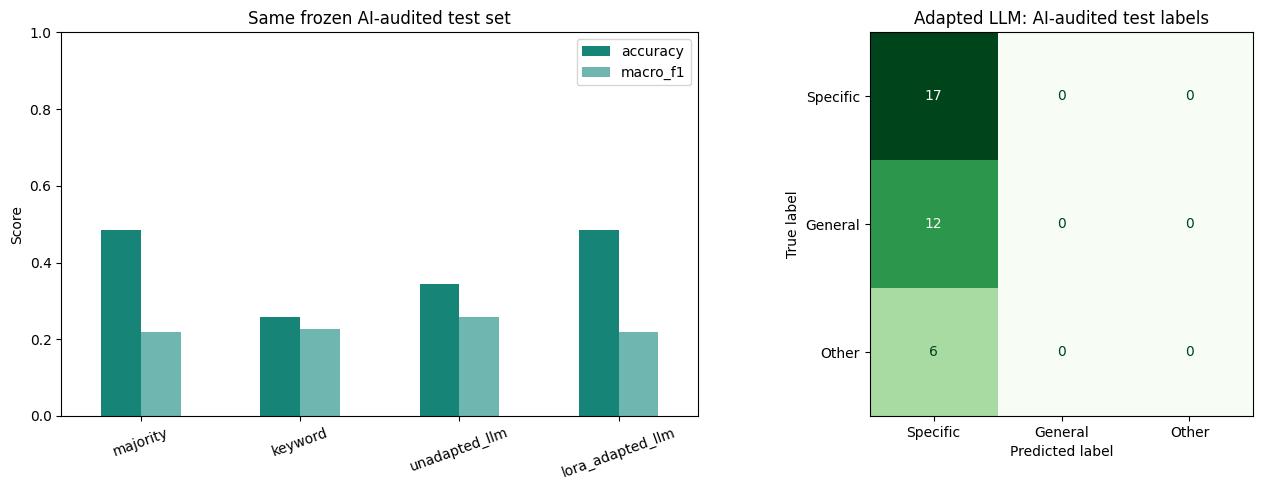

# Results — generated only after real evaluation

Model: Qwen/Qwen2.5-0.5B-Instruct, revision 7ae557604adf67be50417f59c2c2f167def9a775.
Training/validation/test passages: 140/33/35.
Selected epoch: 1, chosen using validation data only.
Labeling method: {'train': 'AI-assisted: passage-by-passage audit by Codex after original human review; NOT independent human labels', 'validation': 'AI-assisted: passage-by-passage audit by Codex after original human review; NOT independent human labels', 'test': 'AI-assisted: passage-by-passage audit by Codex after original human review; NOT independent human labels'}.
Membership was frozen before the initial training hints; later AI audit reviewed every split. No re-splitting occurred.
All labels are AI-assisted, not independent human gold. These metrics measure agreement with audited labels.
Audit manifest SHA-256: 80292047e3857b7150e438dbc01922750dcbc6dbca779b25689b0c5251ec65f3.
GPU smoke test: PASS; it used zero test rows.
Adapted minus original te

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
comparison[["accuracy", "macro_f1"]].plot.bar(ax=axes[0], color=["#168477", "#70b6b0"])
axes[0].set(ylim=(0, 1), title="Same frozen AI-audited test set", ylabel="Score")
axes[0].tick_params(axis="x", rotation=20)
ConfusionMatrixDisplay(np.array(results["lora_adapted_llm"]["confusion_matrix"]),
                       display_labels=["Specific", "General", "Other"]).plot(ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title("Adapted LLM: AI-audited test labels")
fig.tight_layout()
fig.savefig(OUTPUT / "final_comparison.png", dpi=170, bbox_inches="tight")
plt.show()

delta = results["lora_adapted_llm"]["macro_f1"] - results["unadapted_llm"]["macro_f1"]
analysis = f"""# Results — generated only after real evaluation

Model: {MODEL_ID}, revision {RESOLVED_REVISION}.
Training/validation/test passages: {len(splits['train'])}/{len(splits['validation'])}/{len(test)}.
Selected epoch: {best['epoch']}, chosen using validation data only.
Labeling method: {manifest["labeling_method"]}.
Membership was frozen before the initial training hints; later AI audit reviewed every split. No re-splitting occurred.
All labels are AI-assisted, not independent human gold. These metrics measure agreement with audited labels.
Audit manifest SHA-256: {manifest["audit_manifest_sha256"]}.
GPU smoke test: {smoke_record["status"]}; it used zero test rows.
Adapted minus original test macro-F1: {delta:+.4f}.

See test_metrics.json for per-class precision/recall/F1 and confusion matrices;
test_predictions.csv for provenance-linked outputs; adapted_test_errors.csv for errors.

Interpret the actual direction and magnitude of the difference; adaptation need not improve results.
Small grouped test sets have substantial uncertainty. These are descriptive point estimates,
not a statistical significance claim or evidence of performance for all music listeners.

Complete with Aaron's own interpretation before submission:
- Which categories were confused, using concrete errors?
- How did limited/subjective labels, context loss, oldest-first sampling, class balance,
  release-group concentration, and unknown pretraining overlap affect the conclusions?
- How were missing license/attribution fields and any redistribution restrictions handled?
- What did AI actually help with, and what did Aaron independently run, verify, or change?
- What would a larger, independent evaluation test next?
"""
pipeline.write_once(OUTPUT / "RESULTS_AND_LIMITATIONS.md", analysis)
pipeline.save_json(OUTPUT / "completion.json", {"status": "trained_and_evaluated", "finished_at": pipeline.utc_now(),
    "selected_checkpoint": best["checkpoint"], "test_rows": len(test), "versions": VERSIONS, "gpu_smoke_test": smoke_record,
    "labeling_method": manifest["labeling_method"], "independent_human_evaluation": False,
    "audit_manifest_sha256": manifest["audit_manifest_sha256"], "training_bundle_sha256": EXPECTED_BUNDLE_SHA256})
print(analysis)


## Results and interpretation

We fine-tuned **Qwen2.5-0.5B-Instruct** using 140 training passages, with 33 for validation and 35 for the original test. **Epoch 1** had the highest validation macro-F1 and was selected for evaluation. This metric gives each category equal importance.

### Model performance

The adapted model reached **48.6% test accuracy** but classified every passage as a specific musical observation. It missed all general-opinion and background passages. Its macro-F1 fell from **0.258 to 0.218** compared with the original model. Although accuracy increased, performance across the three categories did not improve.

### Limitations

The dataset uses AI-assisted labels with human review. The scores show how closely the model matched these labels. Labeling errors may still affect the results. The small sample and limited passage context also make these findings preliminary.

### Next steps

These results motivated the later validation-only experiments. The original test set was excluded from those runs. Future work should expand the labeled dataset, clarify ambiguous examples and evaluate the model on a fresh, independently human-labeled set.

In [11]:
# Creates a local cloud-runtime archive; it does not publish or upload results.
import shutil
result_archive = shutil.make_archive(str(WORK_DIR / "music_insight_results"), "zip", root_dir=OUTPUT)
print("Results archive:", result_archive)
print("Use Colab's Files pane to download this ZIP to your Mac before the runtime expires.")
print("Also retain the executed notebook and the matching music_insight_AI_AUDITED_training_bundle.zip and notebook 06.")


Results archive: /content/music_insight_j_elzfsr/music_insight_results.zip
Use Colab's Files pane to download this ZIP to your Mac before the runtime expires.
Also retain the executed notebook and the matching music_insight_AI_AUDITED_training_bundle.zip and notebook 06.


Review the generated metrics, confusion matrix, and errors before writing the interpretation. Explain whether adaptation helped, which categories were difficult, and how the sample and annotation decisions limit the findings. The generated analysis file is a starting point to complete after the actual run, not a finished report.

The final submission requires a documented GitHub code URL and a 10–15-minute recorded presentation with 2–3 minutes on GenAI use. Check instructor access to both links. Review record-level licensing before publishing data or adapters. This notebook does not publish files or submit work.

### Use of generative AI

Generative AI assisted with drafting the pipeline and its initial documentation. The project author still needs to run and check the code, provide human annotations, and interpret the findings. The final reflection should describe the assistance and verification that actually occurred; it should not present these drafts or pending experiments as independently completed work.

### References

- [CritiqueBrainz API](https://critiquebrainz.readthedocs.io/api/endpoints.html)
- [Qwen model card](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)
- [PEFT LoRA workflow](https://huggingface.co/docs/peft/v0.17.0/en/quicktour)
- [PyTorch mixed-precision examples](https://docs.pytorch.org/docs/stable/notes/amp_examples.html)

Dependency pins remain in `requirements_colab.txt`. Actual runtime versions and the resolved model revision are recorded in `settings.json`. Fixed seeds reduce variation but do not guarantee bit-identical GPU results.


## Labels and limitations

The dataset uses AI-assisted labels with human review across the training, validation and test sets. The annotation files retain the original choices, audit notes and 21 excluded passages so the labeling decisions can be traced.

The scores measure how closely the model matched these labels. Subjective categories, possible labeling bias and missing passage context may affect the results. The small, oldest-first sample also limits how well the findings represent other music reviews.

A fresh evaluation set labeled independently by multiple individuals would help confirm label effectiveness. Reusing or rearranging the existing passages would not provide an independent test. The saved settings, results and executed notebooks document the experiments.
